In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

%matplotlib inline

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from google.colab import drive
df=pd.read_csv('/content/drive/MyDrive/Insurance_Dirty.csv')

In [5]:
df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19.0,female,27.9,0,yes,southwest,16884.92400
1,18.0,male,33.77,1,no,southeast,1725.55230
2,28.0,male,33.0,3,no,southeast,4449.46200
3,33.0,male,22.705,0,no,northwest,21984.47061
4,32.0,male,28.88,0,no,northwest,3866.85520
5,31.0,Male,25.74,0,no,southeast,3756.62160
6,46.0,female,33.44,1,no,southeast,8240.58960
7,37.0,female,27.74,3,no,northwest,7281.50560
8,37.0,male,29.83,2,YES,northeast,6406.41070
9,60.0,female,25.84,0,no,northwest,28923.13692


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1339 entries, 0 to 1338
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1335 non-null   object 
 1   sex       1337 non-null   object 
 2   bmi       1334 non-null   object 
 3   children  1339 non-null   int64  
 4   smoker    1337 non-null   object 
 5   region    1337 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(1), int64(1), object(5)
memory usage: 73.4+ KB


In [7]:
df.shape

(1339, 7)

In [8]:
df.isnull().sum()

,0
age,4
sex,2
bmi,5
children,0
smoker,2
region,2
charges,2


In [9]:
df.duplicated().sum()

np.int64(2)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
for col in df.columns:
    print(col, df[col].unique())

age ['19.0' '18.0' '28.0' '33.0' '32.0' '31.0' '46.0' '37.0' '60.0' '25.0'
 '62.0' nan '56.0' '27.0' '52.0' '23.0' '30.0' '34.0' '59.0' '63.0' '55.0'
 '22.0' '26.0' '35.0' '24.0' '41.0' '38.0' '36.0' '21.0' '48.0' '40.0'
 '58.0' '53.0' '43.0' '64.0' '20.0' '61.0' '44.0' '57.0' '29.0' '45.0'
 '54.0' '49.0' '47.0' '51.0' '42.0' '50.0' '39.0' 'thirty' ' 45 ' '-5']
sex ['female' 'male' ' Male ' 'FEMALE' nan ' female ']
bmi ['27.9' '33.77' '33.0' '22.705' '28.88' '25.74' '33.44' '27.74' '29.83'
 '25.84' '26.22' '26.29' '34.4' '39.82' '42.13' '24.6' '30.78' '23.845'
 '40.3' '35.3' '36.005' '32.4' '34.1' '31.92' '28.025' '27.72' '23.085'
 '32.775' '17.385' '36.3' '35.6' '26.315' '28.6' nan '36.4' '20.425'
 '32.965' '20.8' '36.67' '39.9' '26.6' '36.63' '21.78' '30.8' '37.05'
 '37.3' '38.665' '34.77' '24.53' '35.2' '35.625' '33.63' '28.0' '34.43'
 '28.69' '36.955' '31.825' '31.68' '22.88' '37.335' '27.36' '33.66' '24.7'
 '25.935' '22.42' '28.9' '39.1' '36.19' '23.98' '24.75' '28.5' '28.1'
 '32.

In [13]:
# Remove extra spaces and make text lowercase
cat_cols = ['sex', 'smoker', 'region']

for col in cat_cols:
    df[col] = df[col].str.strip().str.lower()

In [14]:
df['age'] = df['age'].astype('string').str.strip()
df['age'] = df['age'].replace('thirty', '30')
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['age'].dtype

Float64Dtype()

In [15]:
df['bmi'] = df['bmi'].astype('string').str.strip()
df['bmi'] = pd.to_numeric(df['bmi'], errors='coerce')
df['bmi'].dtype

Float64Dtype()

In [16]:
# Invalid age
df.loc[df['age'] < 0, 'age'] = np.nan

# Invalid BMI
df.loc[df['bmi'] < 0, 'bmi'] = np.nan

# Invalid children
df.loc[df['children'] < 0, 'children'] = np.nan

In [17]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)


age:
<FloatingArray>
[19.0, 18.0, 28.0, 33.0, 32.0, 31.0, 46.0, 37.0, 60.0, 25.0, 62.0, <NA>, 56.0,
 27.0, 52.0, 23.0, 30.0, 34.0, 59.0, 63.0, 55.0, 22.0, 26.0, 35.0, 24.0, 41.0,
 38.0, 36.0, 21.0, 48.0, 40.0, 58.0, 53.0, 43.0, 64.0, 20.0, 61.0, 44.0, 57.0,
 29.0, 45.0, 54.0, 49.0, 47.0, 51.0, 42.0, 50.0, 39.0]
Length: 48, dtype: Float64

sex:
['female' 'male' nan]

bmi:
<FloatingArray>
[  27.9,  33.77,   33.0, 22.705,  28.88,  25.74,  33.44,  27.74,  29.83,
  25.84,
 ...
   39.4,   34.9,   22.0,  30.36,   27.8,  53.13,  39.71,  32.87,   44.7,
  30.97]
Length: 549, dtype: Float64

children:
[ 0.  1.  3.  2.  5.  4. nan]

smoker:
['yes' 'no' nan]

region:
['southwest' 'southeast' 'northwest' 'northeast' nan]

charges:
[16884.924   1725.5523  4449.462  ...  1629.8335  2007.945  29141.3603]

Missing Values:
age         5
sex         2
bmi         6
children    1
smoker      2
region      2
charges     2
dtype: int64

Data Types:
age         Float64
sex          object
bmi         Float64

In [18]:

# Numerical columns
numerical_cols = ['age', 'bmi', 'children']

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns
categorical_cols = ['sex', 'smoker', 'region']

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


In [19]:
df[df['charges'] < 0]

,age,sex,bmi,children,smoker,region,charges
1080,18.0,male,21.78,2.0,no,southeast,-500.0


In [21]:
df = df[df['charges'] >= 0].copy()

In [22]:
# Count negative values
(df['charges'] < 0).sum()

np.int64(0)

In [27]:
df = df.dropna(subset=['charges'])
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


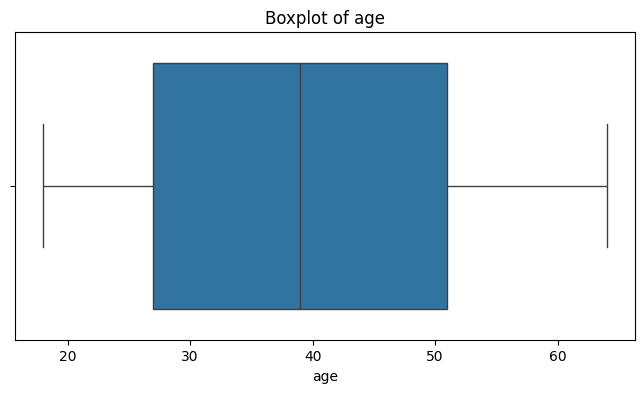

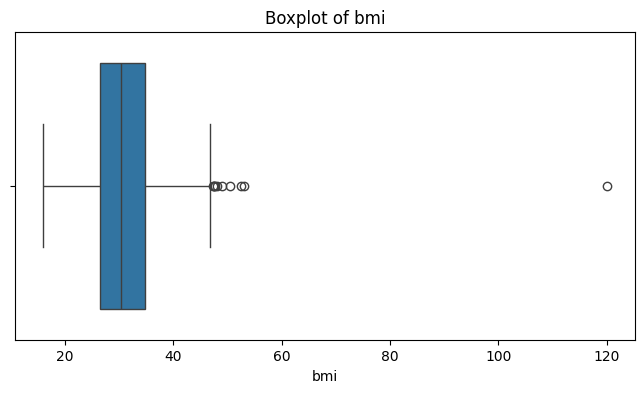

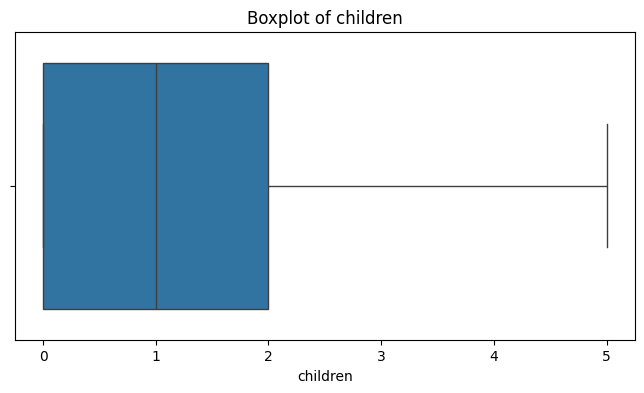

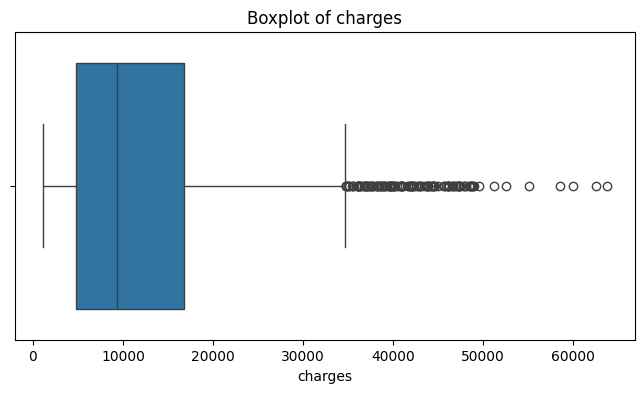

In [28]:
num_cols = ['age', 'bmi', 'children', 'charges']

for col in num_cols:
    plt.figure(figsize=(8, 4))
    sb.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [23]:
num_cols = ['age', 'bmi', 'children', 'charges']
def count_outliers(column):
    q1 = column.quantile(0.25)
    q3 = column.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return ((column < lower_bound) | (column > upper_bound)).sum()
for col in num_cols:
  print(f"{col}:{count_outliers(df[col])} outliers")

age:0 outliers
bmi:10 outliers
children:0 outliers
charges:137 outliers


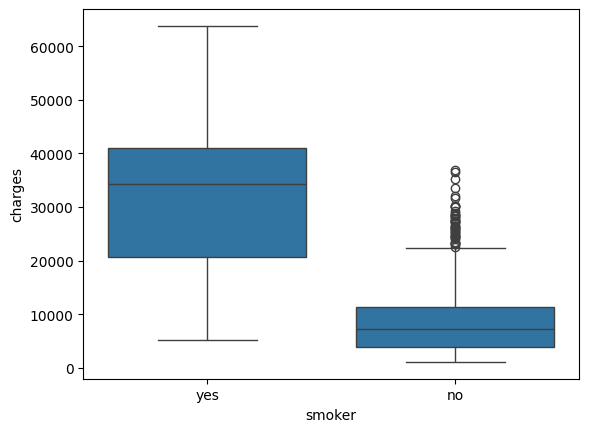

In [24]:
sb.boxplot(data=df, x='smoker', y='charges')
plt.show()

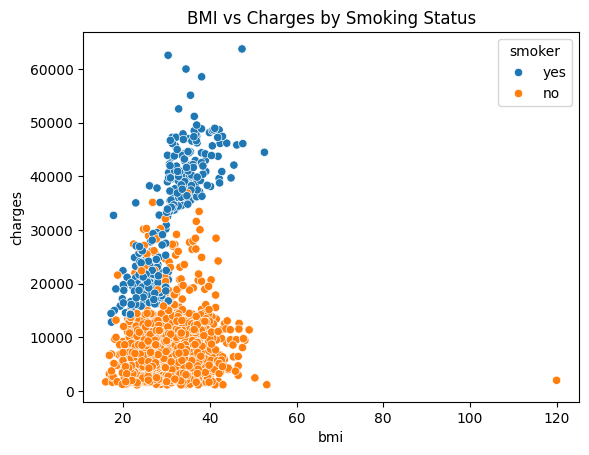

In [26]:
sb.scatterplot(
    data=df,
    x='bmi',
    y='charges',
    hue='smoker'
)

plt.title('BMI vs Charges by Smoking Status')
plt.show()

Insight 1: Smoking has a strong association with higher insurance charges
Insight 2: BMI alone does not explain insurance charges
Insight 3: Non-smokers generally have lower insurance charges

In [29]:
df.loc[
    df['bmi'] > 60,
    ['age', 'sex', 'bmi', 'smoker', 'region', 'charges']
]

,age,sex,bmi,smoker,region,charges
1060,24.0,male,120.0,no,southeast,1981.5819


In [33]:
df=df[df["bmi"]<60].copy()

In [34]:
print(df[df['bmi'] == 120])


Empty DataFrame
Columns: [age, sex, bmi, children, smoker, region, charges]
Index: []


In [37]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicates:")
print(df.duplicated().sum())

print("\nNegative Charges:")
print((df['charges'] < 0).sum())

print("\nNegative Age:")
print((df['age'] < 0).sum())

print("\nNegative BMI:")
print((df['bmi'] < 0).sum())

print("\nNegative Children:")
print((df['children'] < 0).sum())

Dataset Shape: (1333, 7)

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicates:
0

Negative Charges:
0

Negative Age:
0

Negative BMI:
0

Negative Children:
0


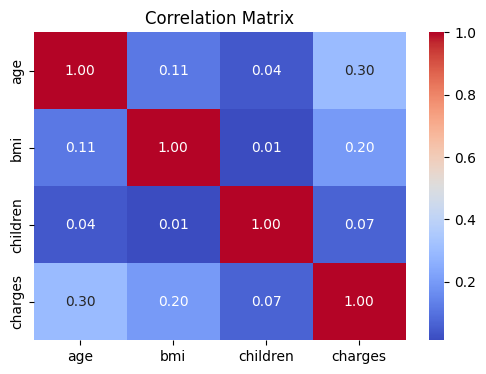

In [36]:
plt.figure(figsize=(6, 4))

sb.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [38]:
def sex(x):
  if x=="male":
    x=0
    return x
  else:
    x=1
    return x
df["sex"]=df["sex"].apply(lambda x :sex(x))



In [39]:
df = pd.get_dummies(
    df,
    columns=['region'],
    dtype=int
)

In [40]:
def smoker(x):
  if x=="no":
    x=0
    return x
  else:
    x=1
    return x
df["smoker"]=df["smoker"].apply(lambda x :smoker(x))



In [41]:
df.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19.0,1,27.9,0.0,1,16884.92400,0,0,0,1
1,18.0,0,33.77,1.0,0,1725.55230,0,0,1,0
2,28.0,0,33.0,3.0,0,4449.46200,0,0,1,0
3,33.0,0,22.705,0.0,0,21984.47061,0,1,0,0
4,32.0,0,28.88,0.0,0,3866.85520,0,1,0,0


In [42]:
x = df.drop('charges', axis=1)
y = df['charges']

In [43]:
from sklearn.model_selection import train_test_split

In [44]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42)

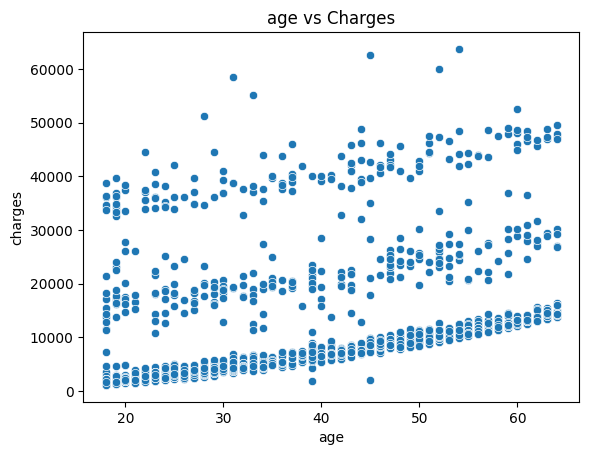

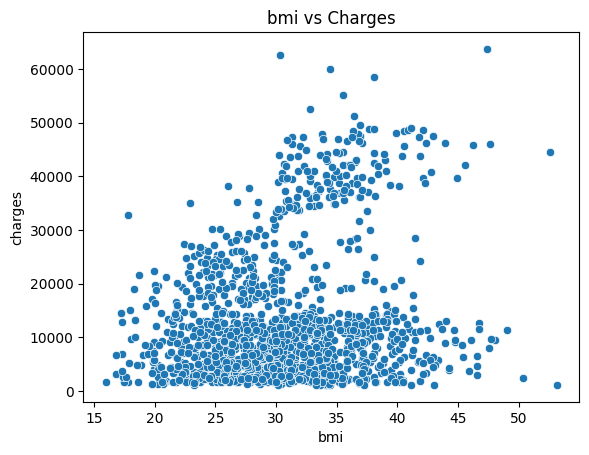

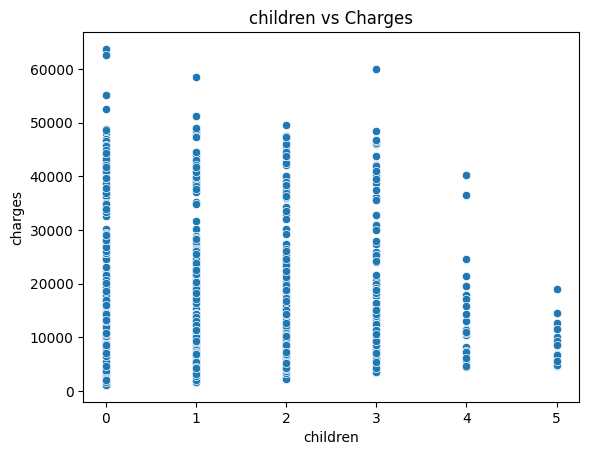

In [45]:
cols = ['age', 'bmi', 'children']

for col in cols:
    sb.scatterplot(data=df, x=col, y='charges')
    plt.title(f'{col} vs Charges')
    plt.show()

In [46]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaler = scaler.fit_transform(x_train_poly)
x_test_scaler = scaler.transform(x_test_poly)
from sklearn.linear_model import LinearRegression
linear_model = LinearRegression()
linear_model.fit(x_train_scaler, y_train)
y_pred = linear_model.predict(x_test_scaler)

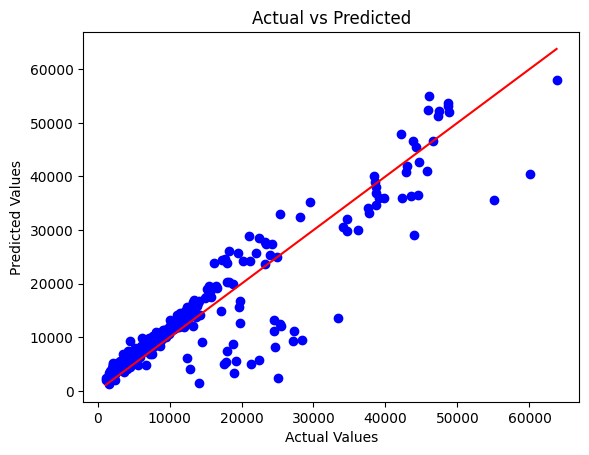

In [47]:
plt.scatter(y_test, y_pred, color='blue')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted')
plt.show()

In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

print("R2 Score:", r2_score(y_test, y_pred))

MAE: 2982.9422134405845
RMSE: 4788.50943458439
R2 Score: 0.8481412364424464


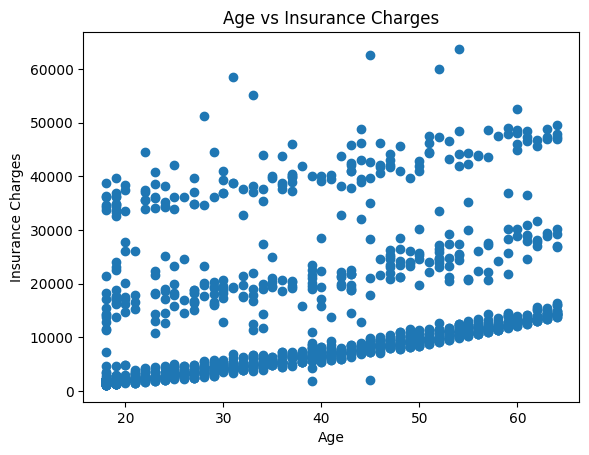

In [49]:
plt.scatter(df['age'], df['charges'])

plt.xlabel('Age')
plt.ylabel('Insurance Charges')
plt.title('Age vs Insurance Charges')

plt.show()

In [50]:
print("Train R2:", r2_score(y_train, linear_model.predict(x_train_scaler)))
print("Test R2:", r2_score(y_test, y_pred))

Train R2: 0.8362163920406654
Test R2: 0.8481412364424464


In [51]:
from google.colab import files

df.to_csv('Cleaned_Data.csv', index=False)

files.download('Cleaned_Data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
df_powerbi=pd.read_csv("/content/drive/MyDrive/Insurance_Dirty.csv")

In [53]:
df_powerbi.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19.0,female,27.9,0,yes,southwest,16884.92400
1,18.0,male,33.77,1,no,southeast,1725.55230
2,28.0,male,33.0,3,no,southeast,4449.46200
3,33.0,male,22.705,0,no,northwest,21984.47061
4,32.0,male,28.88,0,no,northwest,3866.85520
5,31.0,Male,25.74,0,no,southeast,3756.62160
6,46.0,female,33.44,1,no,southeast,8240.58960
7,37.0,female,27.74,3,no,northwest,7281.50560
8,37.0,male,29.83,2,YES,northeast,6406.41070
9,60.0,female,25.84,0,no,northwest,28923.13692


In [54]:
df_powerbi.duplicated().sum()
df_powerbi.drop_duplicates(inplace=True)
df_powerbi.duplicated().sum()

for col in df_powerbi.columns:
    print(col, df_powerbi[col].unique())

# ---------- (مسافات + lowercase) ----------
cat_cols = ['sex', 'smoker', 'region']

for col in cat_cols:
    df_powerbi[col] = df_powerbi[col].str.strip().str.lower()

# ---------- تصحيح نوع البيانات ----------
df_powerbi['age'] = df_powerbi['age'].astype('string').str.strip()
df_powerbi['age'] = df_powerbi['age'].replace('thirty', '30')
df_powerbi['age'] = pd.to_numeric(df_powerbi['age'], errors='coerce')
df_powerbi['age'].dtype

df_powerbi['bmi'] = df_powerbi['bmi'].astype('string').str.strip()
df_powerbi['bmi'] = pd.to_numeric(df_powerbi['bmi'], errors='coerce')
df_powerbi['bmi'].dtype

# ---------- (invalid) ----------
df_powerbi.loc[df_powerbi['age'] < 0, 'age'] = np.nan
df_powerbi.loc[df_powerbi['bmi'] < 0, 'bmi'] = np.nan
df_powerbi.loc[df_powerbi['children'] < 0, 'children'] = np.nan

# مراجعة
for col in df_powerbi.columns:
    print(f"\n{col}:")
    print(df_powerbi[col].unique())

print("\nMissing Values:")
print(df_powerbi.isnull().sum())

print("\nData Types:")
print(df_powerbi.dtypes)

# ---------- Missing values ----------
numerical_cols = ['age', 'bmi', 'children']
for col in numerical_cols:
    df_powerbi[col] = df_powerbi[col].fillna(df_powerbi[col].median())

categorical_cols = ['sex', 'smoker', 'region']
for col in categorical_cols:
    df_powerbi[col] = df_powerbi[col].fillna(df_powerbi[col].mode()[0])

# ---------- charges ----------
df_powerbi[df_powerbi['charges'] < 0]
df_powerbi = df_powerbi.drop(index=1080)
df_powerbi.reset_index(drop=True, inplace=True)

(df_powerbi['charges'] < 0).sum()

df_powerbi = df_powerbi.dropna(subset=['charges'])
df_powerbi.isnull().sum()

# ---------- Outliers ----------
num_cols = ['age', 'bmi', 'children', 'charges']

def count_outliers(column):
    q1 = column.quantile(0.25)
    q3 = column.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return ((column < lower_bound) | (column > upper_bound)).sum()

for col in num_cols:
    print(f"{col}:{count_outliers(df_powerbi[col])} outliers")


df_powerbi.loc[df_powerbi['bmi'] > 60, ['age', 'sex', 'bmi', 'smoker', 'region', 'charges']]
df_powerbi.drop(index=1059, inplace=True)
print(df_powerbi[df_powerbi['bmi'] == 120])

df_powerbi.shape

age ['19.0' '18.0' '28.0' '33.0' '32.0' '31.0' '46.0' '37.0' '60.0' '25.0'
 '62.0' nan '56.0' '27.0' '52.0' '23.0' '30.0' '34.0' '59.0' '63.0' '55.0'
 '22.0' '26.0' '35.0' '24.0' '41.0' '38.0' '36.0' '21.0' '48.0' '40.0'
 '58.0' '53.0' '43.0' '64.0' '20.0' '61.0' '44.0' '57.0' '29.0' '45.0'
 '54.0' '49.0' '47.0' '51.0' '42.0' '50.0' '39.0' 'thirty' ' 45 ' '-5']
sex ['female' 'male' ' Male ' 'FEMALE' nan ' female ']
bmi ['27.9' '33.77' '33.0' '22.705' '28.88' '25.74' '33.44' '27.74' '29.83'
 '25.84' '26.22' '26.29' '34.4' '39.82' '42.13' '24.6' '30.78' '23.845'
 '40.3' '35.3' '36.005' '32.4' '34.1' '31.92' '28.025' '27.72' '23.085'
 '32.775' '17.385' '36.3' '35.6' '26.315' '28.6' nan '36.4' '20.425'
 '32.965' '20.8' '36.67' '39.9' '26.6' '36.63' '21.78' '30.8' '37.05'
 '37.3' '38.665' '34.77' '24.53' '35.2' '35.625' '33.63' '28.0' '34.43'
 '28.69' '36.955' '31.825' '31.68' '22.88' '37.335' '27.36' '33.66' '24.7'
 '25.935' '22.42' '28.9' '39.1' '36.19' '23.98' '24.75' '28.5' '28.1'
 '32.

(1333, 7)

In [55]:
df_powerbi.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df_powerbi.to_csv('Cleaned_PowerBI.csv', index=False)
files.download('Cleaned_PowerBI.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>